## Importações das Bibliotecas Globais e Configurações Iniciais

In [ ]:
import torch
import numpy as np
import seaborn as sns
import torch.nn as nn
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import torch.nn.functional as F
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

np.random.seed(42)
torch.manual_seed(42)

# Configuração do dispositivo (GPU CUDA)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### Preparação dos Dados e Pré-Processamento

In [ ]:
hf_dataset = load_dataset('uoft-cs/cifar10')

# Conversão das imagens para arrays NumPy
x_train = np.array([np.array(img) for img in hf_dataset['train']['img']])
y_train = np.array(hf_dataset['train']['label'])

x_test = np.array([np.array(img) for img in hf_dataset['test']['img']])
y_test = np.array(hf_dataset['test']['label'])

# Conversão para Tensores PyTorch (N, C, H, W) e normalização para [0, 1]
x_train_t = torch.FloatTensor(x_train).permute(0, 3, 1, 2) / 255.0
y_train_t = torch.LongTensor(y_train)

x_test_t = torch.FloatTensor(x_test).permute(0, 3, 1, 2) / 255.0
y_test_t = torch.LongTensor(y_test)

# DataLoaders em memória RAM (execução sem gargalo de CPU)
train_loader = DataLoader(TensorDataset(x_train_t, y_train_t), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(x_test_t, y_test_t), batch_size=128, shuffle=False)

classes = ('Avião', 'Automóvel', 'Pássaro', 'Gato', 'Cervo', 'Cachorro', 'Sapo', 'Cavalo', 'Navio', 'Caminhão')

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

### Configuração e Instanciação do Modelo RESNET-18

In [ ]:
class GPUResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super(GPUResNet18, self).__init__()
        weights = ResNet18_Weights.DEFAULT
        self.backbone = resnet18(weights=weights)

        # Congelar as camadas iniciais do backbone
        for param in self.backbone.parameters():
            param.requires_grad = False

        # Descongelar o último bloco (layer4) para Fine-Tuning
        for param in self.backbone.layer4.parameters():
            param.requires_grad = True

        num_ftrs = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(num_ftrs, num_classes)
        )

        # Buffers da ImageNet para normalizar diretamente na GPU
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        # Redimensionamento 32x32 -> 128x128 em paralelo na GPU
        x = F.interpolate(x, size=(128, 128), mode='bilinear', align_corners=False)
        x = (x - self.mean) / self.std
        return self.backbone(x)

model = GPUResNet18(num_classes=10).to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


### Treinamento do Modelo

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0005)

epochs = 10

for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    print(f"Época [{epoch+1:02d}/{epochs:02d}] - Perda: {epoch_loss:.4f} | Acurácia Treino: {epoch_acc:.2f}%")


Época [01/10] - Perda: 0.3879 | Acurácia Treino: 86.66%
Época [02/10] - Perda: 0.1404 | Acurácia Treino: 95.20%
Época [03/10] - Perda: 0.0712 | Acurácia Treino: 97.60%
Época [04/10] - Perda: 0.0480 | Acurácia Treino: 98.35%
Época [05/10] - Perda: 0.0375 | Acurácia Treino: 98.72%
Época [06/10] - Perda: 0.0318 | Acurácia Treino: 98.92%
Época [07/10] - Perda: 0.0302 | Acurácia Treino: 98.97%
Época [08/10] - Perda: 0.0193 | Acurácia Treino: 99.36%
Época [09/10] - Perda: 0.0232 | Acurácia Treino: 99.29%
Época [10/10] - Perda: 0.0214 | Acurácia Treino: 99.27%


### Avaliação Métrica do Desempenho do Modelo

In [ ]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds, all_labels = np.array(all_preds), np.array(all_labels)

print(classification_report(all_labels, all_preds, target_names=classes))

              precision    recall  f1-score   support

       Avião       0.92      0.95      0.93      1000
   Automóvel       0.96      0.95      0.95      1000
     Pássaro       0.91      0.87      0.89      1000
        Gato       0.84      0.78      0.81      1000
       Cervo       0.90      0.90      0.90      1000
    Cachorro       0.88      0.85      0.86      1000
        Sapo       0.89      0.95      0.92      1000
      Cavalo       0.90      0.95      0.93      1000
       Navio       0.94      0.95      0.95      1000
    Caminhão       0.95      0.93      0.94      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



### Matriz de Confusão

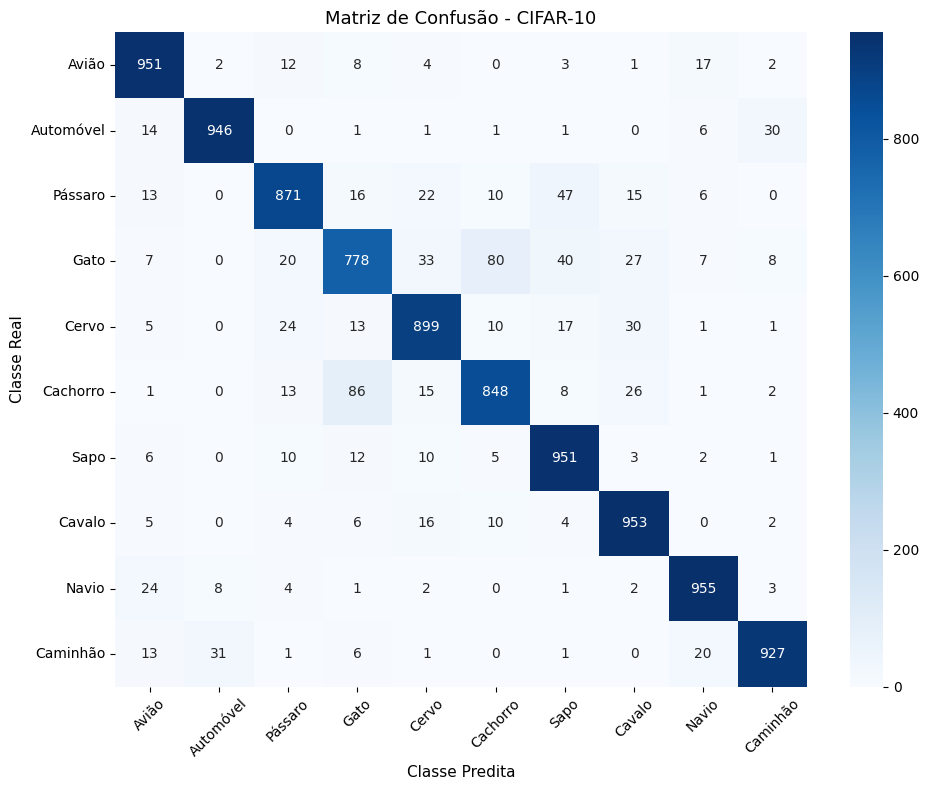

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=True)
plt.title('Matriz de Confusão - CIFAR-10', fontsize=13)
plt.xlabel('Classe Predita', fontsize=11)
plt.ylabel('Classe Real', fontsize=11)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Visualização de Predições Gerais (Acertos e Erros)

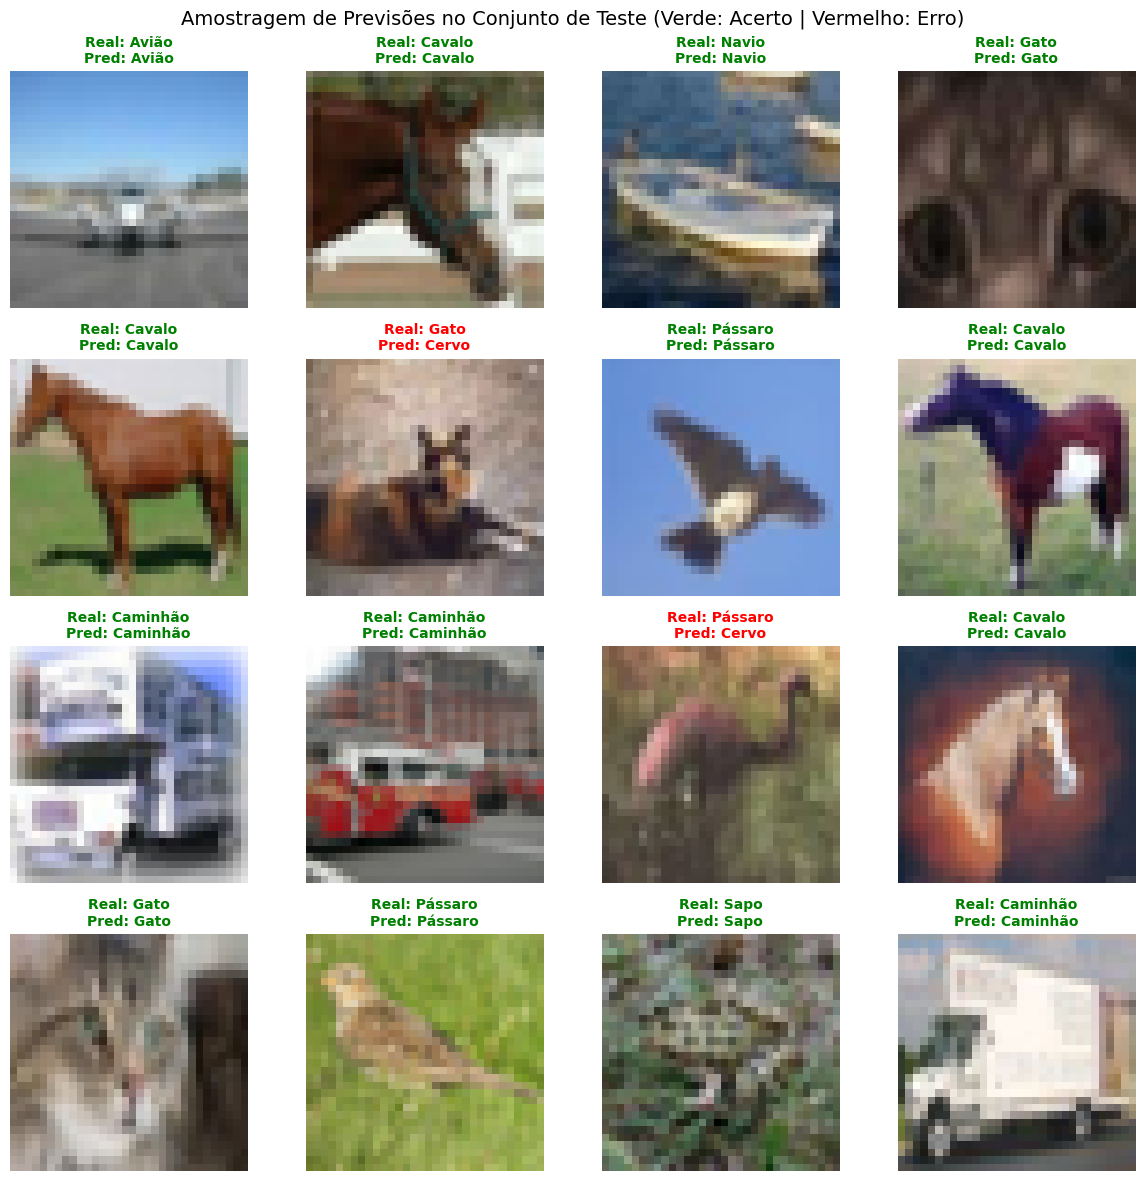

In [ ]:
num_images = 16

indices = np.random.choice(len(all_labels), num_images, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.ravel()

for i, idx in enumerate(indices):
    img = x_test_t[idx].permute(1, 2, 0).numpy()

    true_label = classes[all_labels[idx]]
    pred_label = classes[all_preds[idx]]

    axes[i].imshow(img)
    axes[i].axis('off')

    color = 'green' if true_label == pred_label else 'red'
    axes[i].set_title(
        f'Real: {true_label}\nPred: {pred_label}',
        color=color,
        fontsize=10,
        fontweight='bold',
    )

plt.suptitle(
    'Amostragem de Previsões no Conjunto de Teste (Verde: Acerto | Vermelho: Erro)',
    fontsize=14,
    y=0.98,
)
plt.tight_layout()
plt.show()

### Visualização de Imagens com Erros de Predição

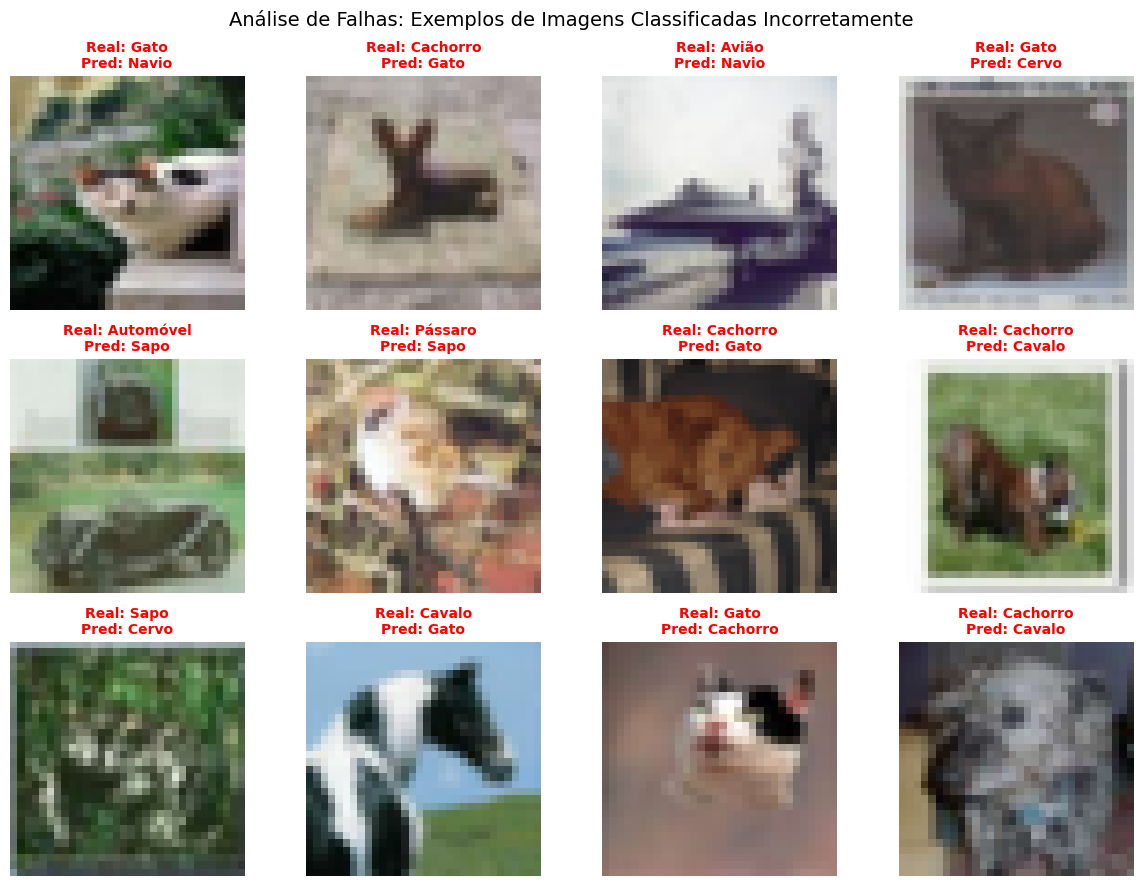

In [ ]:
num_images = 12

error_indices = np.where(all_labels != all_preds)[0]

if len(error_indices) == 0:
    print('O modelo não cometeu erros no conjunto de teste!')

# Selecionar amostras aleatórias dentre os erros
selected_indices = np.random.choice(
    error_indices, min(num_images, len(error_indices)), replace=False
)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.ravel()

for i, idx in enumerate(selected_indices):
    img = x_test_t[idx].permute(1, 2, 0).numpy()

    true_label = classes[all_labels[idx]]
    pred_label = classes[all_preds[idx]]

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(
        f'Real: {true_label}\nPred: {pred_label}',
        color='red',
        fontsize=10,
        fontweight='bold',
    )

plt.suptitle(
    'Análise de Falhas: Exemplos de Imagens Classificadas Incorretamente',
    fontsize=14,
    y=0.98,
)
plt.tight_layout()
plt.show()